# КП — Методи обчислювального інтелекту

Не для кожної задачі є точна формула чи алгоритм. Тоді рішення будують із нечітких правил, налаштовують за даними або шукають еволюційно. Кожна частина КП показує один такий метод на задачі оцінки касових зборів фільму та планування бригад.

| Частина | Задача | Коли беруть такий метод | Кроки |
|---|---|---|---|
| 1. Нечітка система | оцінка касових зборів за словесними правилами | є знання експерта словами, а даних мало | 1–4 |
| 2. Нейро-нечітка модель | прогноз service_cost_kuah за входами | є дані, потрібна модель із зрозумілими правилами | 5–8 |
| 3. Генетичний алгоритм | розподіл об'єктів між бригадами | треба знайти найкращий варіант серед мільйонів комбінацій | 9–11 |

---

Барабаш Катерина · ТВ-61мп · Варіант 2 · `sample.csv`, входи 1–4, вихід service_cost_kuah

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import skfuzzy as fuzz
from skfuzzy import control as ctrl
from sklearn.model_selection import train_test_split
from scipy.optimize import minimize, milp, LinearConstraint, Bounds
import pygad
import warnings
warnings.filterwarnings('ignore')
%matplotlib inline

## Частина 1. Нечітка система

### 1. Підсистема

Лінгвістична змінна — величина, значення якої описують словами: «низький», «середній», «високий». `automf(3, names=TERMS)` ділить діапазон на три трикутні терми. Таблиця 3×3 — це дев'ять правил виду «ЯКЩО x=терм І y=терм ТО z=терм».

**Підсистеми (Варіант 2 — касові збори фільму):**
- 1.1: Якість сценарію × Гра акторів → Якість режисерської роботи
- 1.2: Бюджет фільму × Якість спецефектів → Видовищність
- 1.3: Якість режисерської роботи × Видовищність → Касові збори

In [2]:
TERMS = ["низький", "середній", "високий"]

def fuzzy_system(x_range, y_range, z_range, table, method):
    x = ctrl.Antecedent(np.linspace(*x_range, 201), "x")
    y = ctrl.Antecedent(np.linspace(*y_range, 201), "y")
    z = ctrl.Consequent(np.linspace(*z_range, 201), "z", defuzzify_method=method)
    for var in (x, y, z):
        var.automf(3, names=TERMS)
    rules = [ctrl.Rule(x[TERMS[i]] & y[TERMS[j]], z[table[i][j]])
             for i in range(3) for j in range(3)]
    return ctrl.ControlSystemSimulation(ctrl.ControlSystem(rules))

def infer(ranges, table, method, x_val, y_val):
    sim = fuzzy_system(*ranges, table, method)
    sim.input["x"] = x_val
    sim.input["y"] = y_val
    sim.compute()
    return sim.output["z"]

print("Функцію fuzzy_system побудовано.")

Функцію fuzzy_system побудовано.


### 2. Виведення за Мамдані

Значення 1.1 і 1.2 обчислюються нечітким виведенням із тестової точки варіанту 2 і потім подаються як входи до підсистеми 1.3.

**Два методи дефазифікації для підсистеми 1.3:**
- **Центроїд** — абсциса центру ваги агрегованої фігури (враховує всю площу під кривою виходу).
- **Середнє максимумів (MOM)** — середина ділянки з максимальним ступенем приналежності (орієнтується лише на пік, ігнорує форму решти фігури).

In [3]:
# Межі змінних зі README варіанта 2
RANGES_11 = ((0, 10), (0, 10), (0, 10))    # script quality, actor quality, director quality
RANGES_12 = ((0, 200), (0, 10), (0, 10))   # budget M$, special effects, spectacle
RANGES_13 = ((0, 10), (0, 10), (0, 500))   # director quality, spectacle, box office M$

# Таблиці правил — однакові для всіх трьох підсистем (README variant 2)
BASE_TABLE = [
    ["низький",  "низький",  "середній"],
    ["низький",  "середній", "високий"],
    ["середній", "високий",  "високий"],
]
TABLE_11 = [row[:] for row in BASE_TABLE]
TABLE_12 = [row[:] for row in BASE_TABLE]
TABLE_13 = [row[:] for row in BASE_TABLE]

# Тестова точка: 1.1 x=8.5, y=2.5; 1.2 x=100, y=9.5
out_11 = infer(RANGES_11, TABLE_11, "centroid", 8.5, 2.5)
out_12 = infer(RANGES_12, TABLE_12, "centroid", 100, 9.5)
out_13_centroid = infer(RANGES_13, TABLE_13, "centroid", out_11, out_12)
out_13_mom      = infer(RANGES_13, TABLE_13, "mom",      out_11, out_12)

print(f"1.1  (якість сценарію=8.5, гра акторів=2.5)  →  режисерська якість: {out_11:.4f} балів")
print(f"1.2  (бюджет=100 млн$, спецефекти=9.5)        →  видовищність: {out_12:.4f} балів")
print(f"1.3  центроїд:            {out_13_centroid:.4f} млн $")
print(f"1.3  середнє максимумів:  {out_13_mom:.4f} млн $")

1.1  (якість сценарію=8.5, гра акторів=2.5)  →  режисерська якість: 5.3460 балів
1.2  (бюджет=100 млн$, спецефекти=9.5)        →  видовищність: 7.3824 балів
1.3  центроїд:            276.9289 млн $
1.3  середнє максимумів:  250.0000 млн $


In [4]:
lo_x, hi_x = RANGES_13[0]
lo_y, hi_y = RANGES_13[1]
mid_x = (lo_x + hi_x) / 2
mid_y = (lo_y + hi_y) / 2

u_x = np.linspace(lo_x, hi_x, 201)
u_y = np.linspace(lo_y, hi_y, 201)

abcs_x = {"низький": [lo_x, lo_x, mid_x], "середній": [lo_x, mid_x, hi_x], "високий": [mid_x, hi_x, hi_x]}
abcs_y = {"низький": [lo_y, lo_y, mid_y], "середній": [lo_y, mid_y, hi_y], "високий": [mid_y, hi_y, hi_y]}

mu_x = {t: float(fuzz.interp_membership(u_x, fuzz.trimf(u_x, abc), out_11)) for t, abc in abcs_x.items()}
mu_y = {t: float(fuzz.interp_membership(u_y, fuzz.trimf(u_y, abc), out_12)) for t, abc in abcs_y.items()}

print(f"x={out_11:.4f}  μ: {', '.join(f'{t}={v:.4f}' for t,v in mu_x.items())}")
print(f"y={out_12:.4f}  μ: {', '.join(f'{t}={v:.4f}' for t,v in mu_y.items())}")

rows_s = []
for i, tx in enumerate(TERMS):
    for j, ty in enumerate(TERMS):
        rows_s.append({"x": tx, "y": ty, "z": TABLE_13[i][j], "сила": min(mu_x[tx], mu_y[ty])})

strengths = (pd.DataFrame(rows_s)
               .sort_values("сила", ascending=False)
               .reset_index(drop=True))
display(strengths.style.format({"сила": "{:.6f}"}))

x=5.3460  μ: низький=0.0000, середній=0.9308, високий=0.0692
y=7.3824  μ: низький=0.0000, середній=0.5235, високий=0.4765


,x,y,z,сила
0,середній,середній,середній,0.523529
1,середній,високий,високий,0.476471
2,високий,середній,високий,0.069203
3,високий,високий,високий,0.069203
4,низький,низький,низький,0.000000
5,низький,середній,низький,0.000000
6,низький,високий,середній,0.000000
7,середній,низький,низький,0.000000
8,високий,низький,середній,0.000000


### 3. Поверхня реакції

Поверхня реакції — це повна картина роботи системи: для **кожної** пари значень (режисерська якість, видовищність) вона показує, які касові збори дасть система. Горизонтальні осі — два входи, вертикальна / колір — вихід.

На відміну від тестової точки, де ми отримали одне число, поверхня відповідає на питання: *«А що буде, якщо входи будуть іншими?»*

- **3D-вигляд** (ліворуч) — інтуїтивно показує, де система дає низькі, середні або високі збори.
- **Вид зверху з ізолініями** (праворуч) — зручний для читання точних значень. Лінії з'єднують точки з однаковими зборами.
- **Чорна точка** — тестова точка варіанту 2.

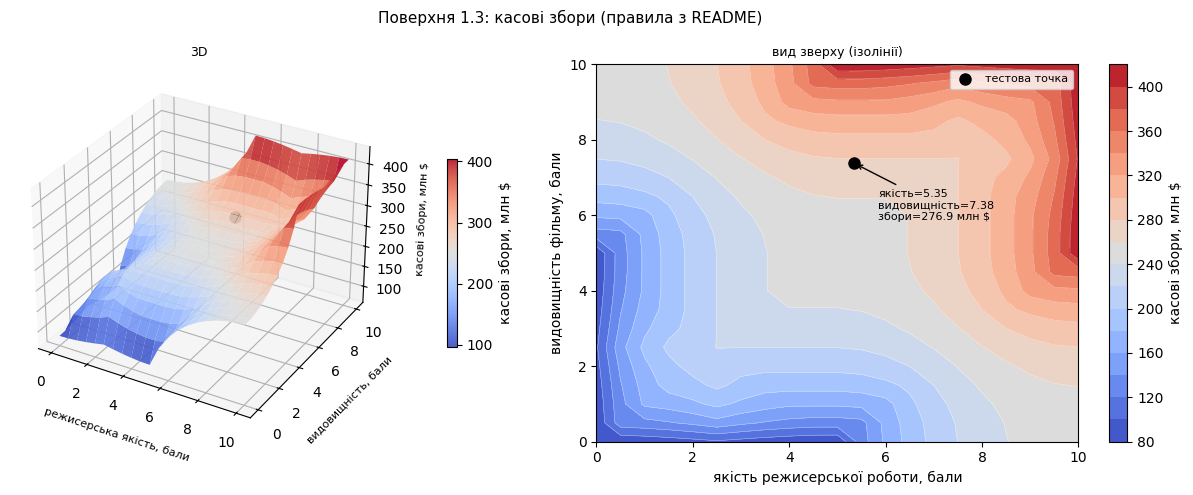

In [5]:
from mpl_toolkits.mplot3d import Axes3D


def surface_13(table):
    xs = np.linspace(*RANGES_13[0], 21)
    ys = np.linspace(*RANGES_13[1], 21)
    sim = fuzzy_system(*RANGES_13, table, "centroid")
    Z = np.zeros((len(ys), len(xs)))
    for i, y_val in enumerate(ys):
        for j, x_val in enumerate(xs):
            sim.input["x"] = x_val
            sim.input["y"] = y_val
            sim.compute()
            Z[i, j] = sim.output["z"]
    return xs, ys, Z


def plot_surface(xs, ys, Z, title, label="касові збори, млн $", test_pt=None, save=None):
    X_mesh, Y_mesh = np.meshgrid(xs, ys)
    fig = plt.figure(figsize=(13, 5))

    ax3 = fig.add_subplot(121, projection="3d")
    surf = ax3.plot_surface(X_mesh, Y_mesh, Z, cmap="coolwarm", alpha=0.9, linewidth=0)
    fig.colorbar(surf, ax=ax3, label=label, shrink=0.5, pad=0.1)
    if test_pt is not None:
        ax3.scatter([test_pt[0]], [test_pt[1]], [test_pt[2]], color="black", s=60, zorder=5)
    ax3.set_xlabel("режисерська якість, бали", fontsize=8, labelpad=6)
    ax3.set_ylabel("видовищність, бали", fontsize=8, labelpad=6)
    ax3.set_zlabel(label, fontsize=8)
    ax3.set_title("3D", fontsize=9)

    ax2 = fig.add_subplot(122)
    cf = ax2.contourf(xs, ys, Z, levels=20, cmap="coolwarm")
    ax2.contour(xs, ys, Z, levels=20, colors="white", linewidths=0.4, alpha=0.5)
    fig.colorbar(cf, ax=ax2, label=label)
    if test_pt is not None:
        ax2.plot(test_pt[0], test_pt[1], "ko", markersize=8, label="тестова точка")
        ax2.annotate(
            f"якість={test_pt[0]:.2f}\nвидовищність={test_pt[1]:.2f}\nзбори={test_pt[2]:.1f} млн $",
            xy=(test_pt[0], test_pt[1]),
            xytext=(test_pt[0] + 0.5, test_pt[1] - 1.5),
            fontsize=8,
            arrowprops=dict(arrowstyle="->", color="black"),
        )
        ax2.legend(fontsize=8)
    ax2.set_xlabel("якість режисерської роботи, бали")
    ax2.set_ylabel("видовищність фільму, бали")
    ax2.set_title("вид зверху (ізолінії)", fontsize=9)

    fig.suptitle(title, fontsize=11)
    fig.tight_layout()
    if save:
        fig.savefig(save, dpi=100, bbox_inches="tight")
    plt.show()


xs, ys, Z_old = surface_13(TABLE_13)
plot_surface(xs, ys, Z_old, "Поверхня 1.3: касові збори (правила з README)",
             test_pt=(out_11, out_12, out_13_centroid), save="task21_mf.png")

### 4. Одне правило

Змінимо правило «режисерська якість середня І видовищність середня → збори середні» на «→ збори високі» і подивимося, як поверхня змінилася саме там, де це правило спрацьовує.

Порівняння до/після зміни правила 1.3:
  центроїд:           було 276.9289 → стало 403.8532 млн $  (різниця +126.9243)
  середнє максимумів: було 250.0000 → стало 440.0180 млн $  (різниця +190.0180)


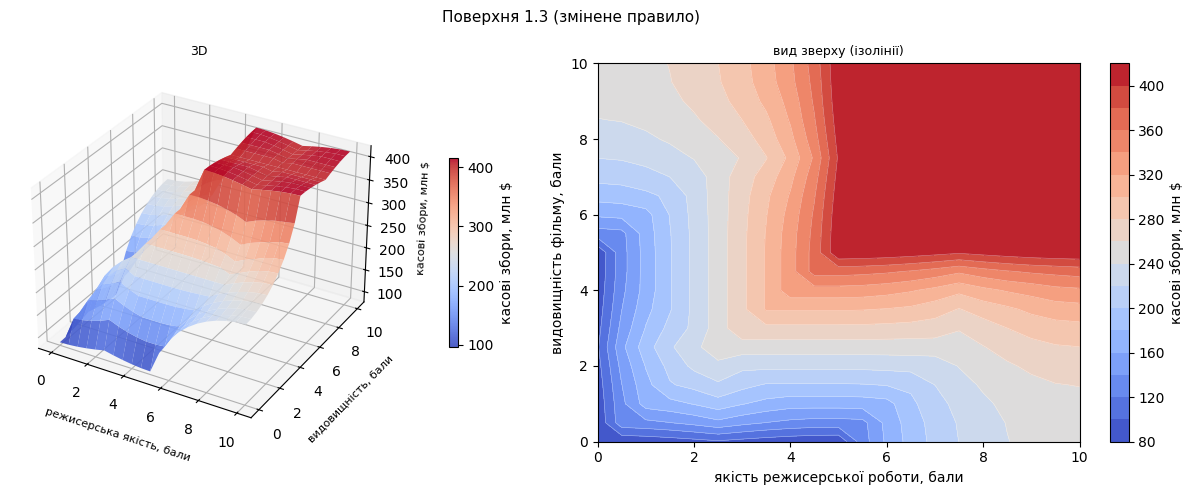

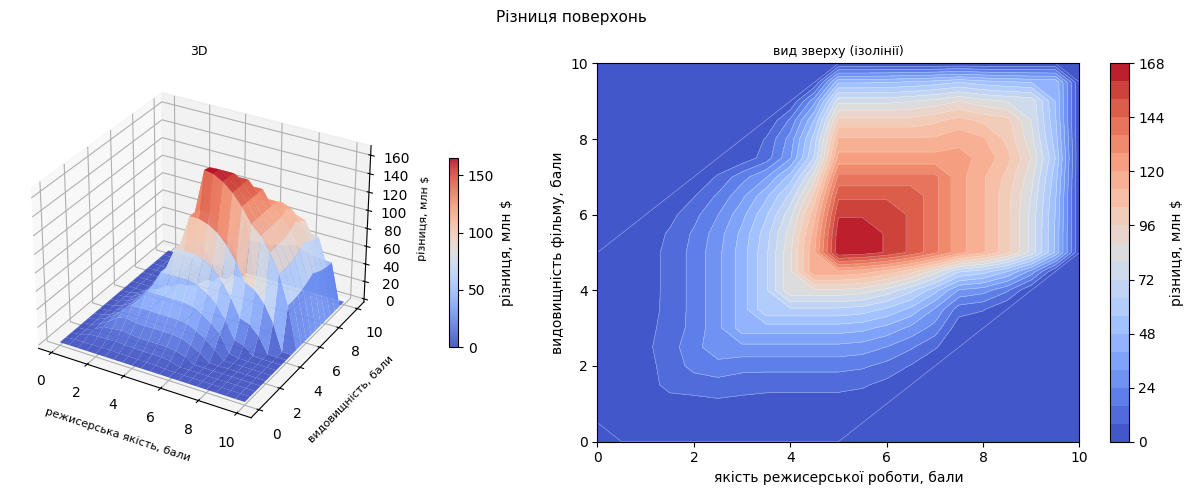

In [6]:
TABLE_13_NEW = [row[:] for row in TABLE_13]
TABLE_13_NEW[1][1] = "високий"

new_centroid = infer(RANGES_13, TABLE_13_NEW, "centroid", out_11, out_12)
new_mom      = infer(RANGES_13, TABLE_13_NEW, "mom",      out_11, out_12)

print("Порівняння до/після зміни правила 1.3:")
print(f"  центроїд:           було {out_13_centroid:.4f} → стало {new_centroid:.4f} млн $  (різниця {new_centroid-out_13_centroid:+.4f})")
print(f"  середнє максимумів: було {out_13_mom:.4f} → стало {new_mom:.4f} млн $  (різниця {new_mom-out_13_mom:+.4f})")

_, _, Z_new = surface_13(TABLE_13_NEW)

plot_surface(xs, ys, Z_new, "Поверхня 1.3 (змінене правило)")
plot_surface(xs, ys, Z_new - Z_old, "Різниця поверхонь", label="різниця, млн $",
             save="task21_inference.png")

---

## Частина 2. Нейро-нечітка модель

### 5. Дані

Модель Сугено нульового порядку: «ЯКЩО входи близькі до центру правила ТО y = число». Вихід — середнє висновків правил, зважене ступенями активації. Похибка — **RMSE** (корінь із середньоквадратичної похибки): менше = точніше.

**Варіант 2:** `sample.csv`, входи 1–4, вихід `service_cost_kuah`.

---

**Навчальна і тестова вибірки**

З 61 рядка 75% (45 точок) відкладено для **навчання** — модель підбирає свої параметри саме на них.  
Решта 25% (16 точок) утворюють **тестову** вибірку — модель їх під час навчання не бачила.

| | Навчальна RMSE | Тестова RMSE |
|---|---|---|
| **Що вимірює** | наскільки модель підійшла до даних, на яких вчилась | наскільки добре вона працює на нових, невідомих даних |
| **Мала** | модель добре описує навчальні дані | модель справді узагальнює — це хороший знак |
| **Велика** | модель не навчилась навіть на своїх даних | тестова >> навчальна → перенавчання: запам'ятала, але не узагальнила |

**Базова лінія — прогноз середнім:** «модель», що завжди повертає середнє значення навчальної вибірки. Будь-яка нечітка модель повинна давати RMSE нижчу за цей рівень.

In [7]:
sample = pd.read_csv("sample.csv")
X = sample.iloc[:, :-1]
y = sample.iloc[:, -1]

X_tr, X_te, y_tr, y_te = train_test_split(X.to_numpy(), y.to_numpy(), test_size=0.25, random_state=0)

x_min, x_max = X_tr.min(axis=0), X_tr.max(axis=0)
x_tr = (X_tr - x_min) / (x_max - x_min)
x_te = (X_te - x_min) / (x_max - x_min)

y_min  = y_tr.min()
y_span = y_tr.max() - y_tr.min()
t_tr = (y_tr - y_min) / y_span
t_te = (y_te - y_min) / y_span

rmse_mean_tr = float(np.sqrt(np.mean((y_tr - y_tr.mean()) ** 2)))
rmse_mean_te = float(np.sqrt(np.mean((y_te - y_tr.mean()) ** 2)))

overview = pd.DataFrame([
    {"": "Кількість точок",
     "Навчальна вибірка\n(модель на ній вчиться)": f"{X_tr.shape[0]} спостережень × {X_tr.shape[1]} входи",
     "Тестова вибірка\n(модель їх не бачила)": f"{X_te.shape[0]} спостережень × {X_te.shape[1]} входи"},
    {"": "Базова лінія RMSE\n(прогноз середнім)",
     "Навчальна вибірка\n(модель на ній вчиться)": f"{rmse_mean_tr:.4f}",
     "Тестова вибірка\n(модель їх не бачила)": f"{rmse_mean_te:.4f}"},
]).set_index("")

display(overview)

,Навчальна вибірка\n(модель на ній вчиться),Тестова вибірка\n(модель їх не бачила)
,,
Кількість точок,45 спостережень × 4 входи,16 спостережень × 4 входи
Базова лінія RMSE\n(прогноз середнім),1.0168,0.8919


In [8]:
# Ядро моделі Сугено (готове)
def unpack(theta, c):
    k = c * x_tr.shape[1]
    return theta[:k].reshape(c, -1), np.exp(theta[k:2 * k]).reshape(c, -1), theta[2 * k:]

def activation(theta, x, c):
    centers, widths, _ = unpack(theta, c)
    z = -0.5 * (((x[:, None, :] - centers[None]) / widths[None]) ** 2).sum(axis=2)
    e = np.exp(z - z.max(axis=1, keepdims=True))
    return e / e.sum(axis=1, keepdims=True)

def rmse(theta, x, t, c):
    return float(np.sqrt(np.mean((activation(theta, x, c) @ unpack(theta, c)[2] - t) ** 2)))

def errors(theta, c):
    return rmse(theta, x_tr, t_tr, c) * y_span, rmse(theta, x_te, t_te, c) * y_span

def pack(centers, widths):
    c = len(centers)
    theta = np.concatenate([np.ravel(centers), np.log(np.ravel(widths)), np.zeros(c)])
    w = activation(theta, x_tr, c)
    theta[2 * c * x_tr.shape[1]:] = np.linalg.solve(w.T @ w + 1e-8 * np.eye(c), w.T @ t_tr)
    return theta

def tune(theta, c):
    n = c * x_tr.shape[1]
    bounds = [(-0.05, 1.05)] * n + [(np.log(0.08), np.log(0.8))] * n + [(-0.05, 1.05)] * c
    res = minimize(rmse, np.clip(theta, *np.array(bounds).T), args=(x_tr, t_tr, c),
                   method="L-BFGS-B", bounds=bounds, options={"maxiter": 2000})
    return res.x

print("Ядро моделі готове.")

Ядро моделі готове.


### 6. Субтрактивна кластеризація

Субтрактивна кластеризація сама визначає кількість кластерів (правил). Малий радіус `ra` → багато дрібних кластерів, великий → кілька великих.

In [9]:
def subclust(data, ra, accept=0.5, reject=0.15):
    a, b = 4 / ra ** 2, 4 / (1.5 * ra) ** 2
    potential = np.exp(-a * ((data[:, None, :] - data[None, :, :]) ** 2).sum(-1)).sum(1)
    first, centers = potential.max(), []
    while True:
        k = int(potential.argmax())
        top = potential[k]
        if top < reject * first:
            break
        if top < accept * first:
            nearest = min(np.sqrt(((data[k] - data[c]) ** 2).sum()) for c in centers)
            if nearest / ra + top / first < 1:
                potential[k] = 0
                continue
        centers.append(k)
        potential = np.maximum(potential - top * np.exp(-b * ((data - data[k]) ** 2).sum(1)), 0)
    return data[centers]

data_sc = np.column_stack([x_tr, t_tr])

sc_rows = []
for ra in (0.3, 0.5, 0.8):
    c = len(subclust(data_sc, ra))
    sc_rows.append({"ra (радіус кластеризації)": ra, "Правил (кластерів)": c})

display(pd.DataFrame(sc_rows))

,ra (радіус кластеризації),Правил (кластерів)
0,0.3,28
1,0.5,8
2,0.8,3


### 7. Правила з c-means і налаштування

C-means кластеризація задає фіксовану кількість правил і розміщує центри там, де дані найгустіші. Після ініціалізації центрів — **налаштування** оптимізує центри, ширини гаусіан і вихідні константи методом L-BFGS-B, мінімізуючи RMSE на навчальних даних.

In [10]:
def cmeans_rules(c):
    cntr, u, *_ = fuzz.cluster.cmeans(
        np.column_stack([x_tr, t_tr]).T, c=c, m=2.0, error=1e-6, maxiter=1000, seed=0)
    centers = cntr[:, :x_tr.shape[1]]
    widths = np.array([
        np.sqrt((u[k] ** 2 @ (x_tr - centers[k]) ** 2) / (u[k] ** 2).sum())
        for k in range(c)
    ])
    return pack(centers, np.clip(widths, 0.08, 0.8))

theta       = cmeans_rules(3)
theta_tuned = tune(theta, 3)

tr_b, te_b = errors(theta, 3)
tr_a, te_a = errors(theta_tuned, 3)

rows_m = [
    {"Модель": "Прогноз середнім (базова лінія)",
     "Навчальна RMSE\n(45 точок)": round(rmse_mean_tr, 4),
     "Тестова RMSE\n(16 нових точок)": round(rmse_mean_te, 4),
     "Висновок": "Завжди повертає середнє — не враховує входи. Це мінімальна планка, яку модель має перевищити."},
    {"Модель": "3 правила c-means, до налаштування",
     "Навчальна RMSE\n(45 точок)": round(tr_b, 4),
     "Тестова RMSE\n(16 нових точок)": round(te_b, 4),
     "Висновок": "Тестова RMSE нижча за базову — модель справді навчилась і добре узагальнює на нових даних."},
    {"Модель": "3 правила c-means, після налаштування",
     "Навчальна RMSE\n(45 точок)": round(tr_a, 4),
     "Тестова RMSE\n(16 нових точок)": round(te_a, 4),
     "Висновок": "Навчальна похибка зменшилась, але тестова зросла — ознака перенавчання на малій вибірці."},
]
df_m = pd.DataFrame(rows_m)
best_te_idx = df_m["Тестова RMSE\n(16 нових точок)"].idxmin()

def highlight_best_m(row):
    return ["background-color: #d4edda; font-weight: bold"
            if row.name == best_te_idx else "" for _ in row]

display(df_m.style.apply(highlight_best_m, axis=1)
              .format({"Навчальна RMSE\n(45 точок)": "{:.4f}",
                       "Тестова RMSE\n(16 нових точок)": "{:.4f}"}))

,Модель,Навчальна RMSE (45 точок),Тестова RMSE (16 нових точок),Висновок
0,Прогноз середнім (базова лінія),1.0168,0.8919,"Завжди повертає середнє — не враховує входи. Це мінімальна планка, яку модель має перевищити."
1,"3 правила c-means, до налаштування",0.7801,0.7935,Тестова RMSE нижча за базову — модель справді навчилась і добре узагальнює на нових даних.
2,"3 правила c-means, після налаштування",0.4858,1.1160,"Навчальна похибка зменшилась, але тестова зросла — ознака перенавчання на малій вибірці."


### 8. Кількість правил

Малo правил — модель занадто груба. Багато — перенавчання. Таблиця і графік показують, де тестова RMSE найменша — це оптимальна кількість правил.

,Правил,Навчальна RMSE (45 точок),Тестова RMSE (16 нових точок)
0,2,0.6853,0.8423
1,3,0.4858,1.1160
2,4,0.4751,1.1655
3,5,0.3847,0.8045
4,6,0.2975,0.9694


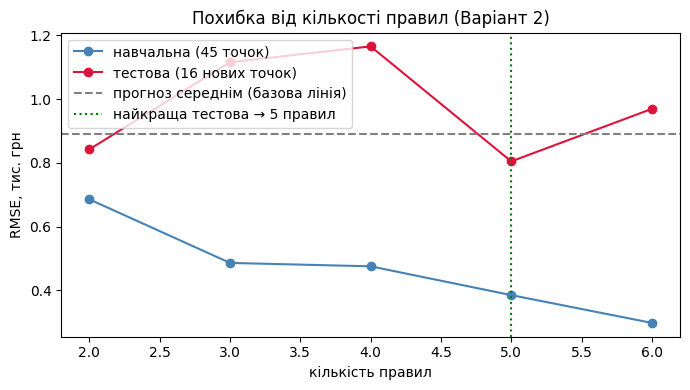

In [11]:
rule_rows = []
for c in range(2, 7):
    th = tune(cmeans_rules(c), c)
    tr_e, te_e = errors(th, c)
    rule_rows.append({"Правил": c,
                      "Навчальна RMSE\n(45 точок)": round(tr_e, 4),
                      "Тестова RMSE\n(16 нових точок)": round(te_e, 4)})

rules_df = pd.DataFrame(rule_rows)
best_idx = rules_df["Тестова RMSE\n(16 нових точок)"].idxmin()

def highlight_best(row):
    return ["background-color: #d4edda; font-weight: bold"
            if row.name == best_idx else "" for _ in row]

display(rules_df.style.apply(highlight_best, axis=1)
                   .format({"Навчальна RMSE\n(45 точок)": "{:.4f}",
                             "Тестова RMSE\n(16 нових точок)": "{:.4f}"}))

best_c = int(rules_df.loc[best_idx, "Правил"])

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(rules_df["Правил"], rules_df["Навчальна RMSE\n(45 точок)"],
        marker="o", color="steelblue", label="навчальна (45 точок)")
ax.plot(rules_df["Правил"], rules_df["Тестова RMSE\n(16 нових точок)"],
        marker="o", color="crimson", label="тестова (16 нових точок)")
ax.axhline(rmse_mean_te, color="gray", linestyle="--", label="прогноз середнім (базова лінія)")
ax.axvline(best_c, color="green", linestyle=":", linewidth=1.5,
           label=f"найкраща тестова → {best_c} правил")
ax.set_xlabel("кількість правил")
ax.set_ylabel("RMSE, тис. грн")
ax.set_title("Похибка від кількості правил (Варіант 2)")
ax.legend()
fig.tight_layout()
plt.savefig("anfis_training_error.png", dpi=100, bbox_inches="tight")
plt.show()

---

## Частина 3. Розподіл бригад

### 9. Задача й жадібний алгоритм

**Об'єкти** — рядки з `sample.csv`. Кожен описується двома числами:
- **t** = 0.5 + contracted_power_kw / 8 — час обслуговування одного об'єкта (год)
- **v** = service_cost_kuah — цінність: вартість послуги, яку отримаємо, якщо обслугуємо цей об'єкт

**Мета:** відібрати об'єкти та розподілити їх між трьома бригадами (фонд: 8 / 5 / 5 год) так, щоб **сума v** призначених об'єктів була максимальною, а жодна бригада не перевищила свій фонд.

**Терміни результатів:**

| Термін | Що означає |
|---|---|
| **Сума цінності** | Σ v для всіх призначених об'єктів — чим більше, тим краще |
| **Завантаження [a / b / c]** | години, витрачені кожною бригадою: [бр.1, бр.2, бр.3] |
| **Перевищення** | сума годин понад фонд по всіх бригадах; 0 = план допустимий |

**Жадібний алгоритм** сортує об'єкти за спаданням v/t (цінність за годину) і кладе кожен у першу бригаду, де він ще вміщується за фондом. Не перебирає комбінації — швидкий, але може пропустити кращий розподіл.

In [12]:
FUND     = (8, 5, 5)
TIME_DIV = 8

t = 0.5 + sample["contracted_power_kw"].to_numpy() / TIME_DIV
v = sample["service_cost_kuah"].to_numpy()

setup = pd.DataFrame([
    {"Параметр": "Кількість об'єктів",         "Значення": str(len(t))},
    {"Параметр": "Сумарний час усіх об'єктів", "Значення": f"{t.sum():.2f} год"},
    {"Параметр": "Доступний фонд (всього)",     "Значення": f"{sum(FUND)} год  (бр.1: {FUND[0]}  · бр.2: {FUND[1]}  · бр.3: {FUND[2]})"},
    {"Параметр": "Покриття фондом",             "Значення": f"{100*sum(FUND)/t.sum():.1f}% від сумарного часу"},
]).set_index("Параметр")
display(setup)

,Значення
Параметр,
Кількість об'єктів,61
Сумарний час усіх об'єктів,164.79 год
Доступний фонд (всього),18 год (бр.1: 8 · бр.2: 5 · бр.3: 5)
Покриття фондом,10.9% від сумарного часу


In [13]:
def load(plan):
    return [float(t[plan == b].sum()) for b in (1, 2, 3)]

def overflow(plan):
    return float(sum(max(0.0, used - f) for used, f in zip(load(plan), FUND)))

def value(plan):
    return float(v[plan > 0].sum())

def repair(plan):
    plan = np.asarray(plan, int).copy()
    for b, f in enumerate(FUND, start=1):
        idx  = np.flatnonzero(plan == b)
        used = t[idx].sum()
        for i in idx[np.argsort(v[idx] / t[idx])]:
            if used <= f + 1e-9:
                break
            plan[i], used = 0, used - t[i]
    return plan

def show(name, plan):
    ld = load(plan)
    ov = overflow(plan)
    brigade_str = "  ·  ".join(f"бр.{b+1}: {ld[b]:.3f} з {FUND[b]}" for b in range(3))
    print(f"{name}")
    print(f"  сума цінності: {value(plan):.3f}")
    print(f"  завантаження бригад: {sum(ld):.3f} год  ({brigade_str})")
    print(f"  перевищення фонду: {ov:.6f} год")

print("Допоміжні функції готові.")

Допоміжні функції готові.


In [14]:
plan_greedy = np.zeros(len(t), dtype=int)
used_b = [0.0, 0.0, 0.0]
for i in np.argsort(-(v / t)):
    for b in range(3):
        if used_b[b] + t[i] <= FUND[b] + 1e-9:
            plan_greedy[i] = b + 1
            used_b[b] += t[i]
            break

show("жадібний алгоритм", plan_greedy)

жадібний алгоритм
  сума цінності: 24.587
  завантаження бригад: 16.602 год  (бр.1: 7.277 з 8  ·  бр.2: 4.402 з 5  ·  бр.3: 4.922 з 5)
  перевищення фонду: 0.000000 год


### 10. Генетичний алгоритм

**Генетичний алгоритм (ГА)** імітує природний відбір: зберігає популяцію з 120 розподілів (хромосом), кожне покоління відбирає кращих батьків, схрещує їх і вносить випадкові мутації. Після 250 поколінь повертає найкращий знайдений розподіл.

Два варіанти обробки обмежень:

| Варіант | Як дотримується фонд часу |
|---|---|
| **ГА з ремонтом** | після мутації «відремонтовує» план — прибирає найменш цінні об'єкти, доки кожна бригада вкладається у фонд. Завжди повертає допустимий план |
| **ГА зі штрафом** | дозволяє бригаді перевищити фонд, але штрафує: фітнес = Σv − 10 × перевищення. Може залишити порушення, якщо штраф занадто малий |

In [15]:
def run_ga(fitness):
    ga = pygad.GA(
        num_generations=250, sol_per_pop=120, num_parents_mating=60,
        num_genes=len(t), gene_type=int, gene_space=[0, 1, 2, 3],
        fitness_func=fitness,
        parent_selection_type="tournament", K_tournament=3,
        crossover_type="uniform",
        mutation_type="random", mutation_num_genes=max(1, len(t) // 20),
        keep_elitism=4, random_seed=0, suppress_warnings=True)
    ga.run()
    return np.asarray(ga.best_solution()[0], int)

plan_repair = repair(run_ga(lambda ga, sol, idx: value(repair(sol))))
show("ГА з ремонтом", plan_repair)

ГА з ремонтом
  сума цінності: 25.044
  завантаження бригад: 17.364 год  (бр.1: 7.919 з 8  ·  бр.2: 4.680 з 5  ·  бр.3: 4.765 з 5)
  перевищення фонду: 0.000000 год


In [16]:
plan_penalty = run_ga(lambda ga, sol, idx: value(sol) - 10 * overflow(sol))
show("ГА зі штрафом", plan_penalty)

ГА зі штрафом
  сума цінності: 17.566
  завантаження бригад: 17.009 год  (бр.1: 7.035 з 8  ·  бр.2: 5.134 з 5  ·  бр.3: 4.840 з 5)
  перевищення фонду: 0.134125 год


### 11. Точний оптимум

MILP (мішано-цілочисельне лінійне програмування) перебирає всі допустимі розподіли й гарантує глобальний максимум. Результат — верхня межа, з якою порівнюються всі евристики.

,План,Сума цінності (Σv),"Завантаження, год (бр.1 / бр.2 / бр.3)","Перевищення, год",% від оптимуму
0,жадібний алгоритм,24.587,7.277 / 4.402 / 4.922,0.000000,96.1
1,ГА з ремонтом,25.044,7.919 / 4.680 / 4.765,0.000000,97.9
2,ГА зі штрафом,17.566,7.035 / 5.134 / 4.840,0.134125,68.7
3,оптимум,25.586,7.961 / 4.784 / 4.708,0.000000,100.0


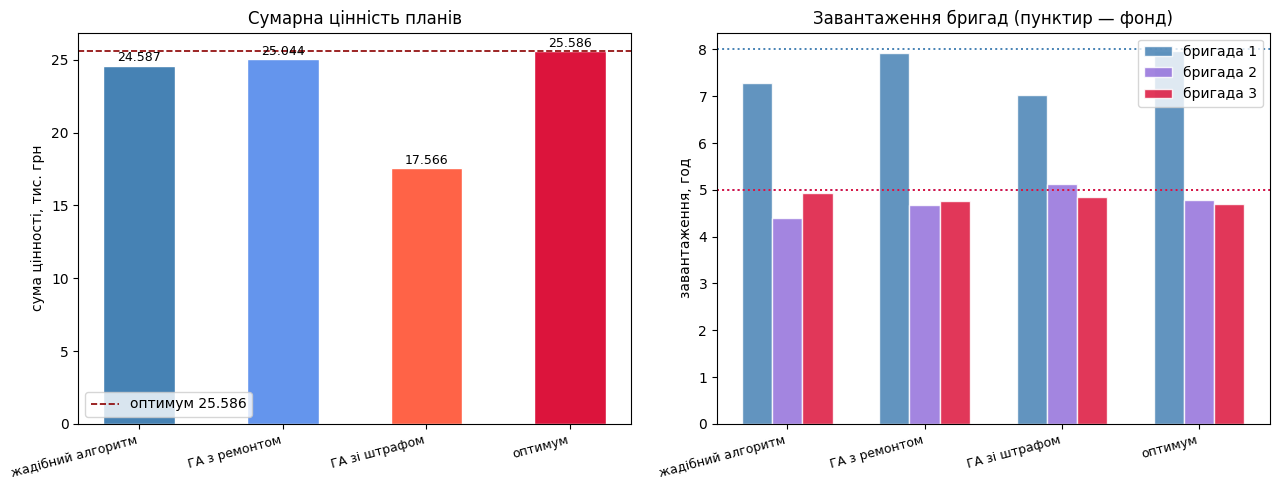

In [17]:
def optimum():
    n = len(t)
    rows = [np.concatenate([t if b == k else np.zeros(n) for k in range(3)]) for b in range(3)]
    rows += [np.tile(np.eye(n)[i], 3) for i in range(n)]
    res = milp(-np.tile(v, 3), integrality=np.ones(3 * n), bounds=Bounds(0, 1),
               constraints=LinearConstraint(np.array(rows),
                                            [0] * (3 + n), list(FUND) + [1] * n))
    return (np.arange(1, 4)[:, None] * np.round(res.x).reshape(3, n)).sum(0).astype(int)

plan_optimum = optimum()
best = value(plan_optimum)

plans = [
    ("жадібний алгоритм", plan_greedy),
    ("ГА з ремонтом",     plan_repair),
    ("ГА зі штрафом",     plan_penalty),
    ("оптимум",           plan_optimum),
]
rows_p = []
for name, p in plans:
    ld = load(p)
    rows_p.append({
        "План": name,
        "Сума цінності (Σv)": round(value(p), 3),
        "Завантаження, год\n(бр.1 / бр.2 / бр.3)": " / ".join(f"{x:.3f}" for x in ld),
        "Перевищення, год": overflow(p),
        "% від оптимуму": round(100 * value(p) / best, 1),
    })

df_plans = pd.DataFrame(rows_p)
best_plan_idx = df_plans["Сума цінності (Σv)"].idxmax()

def highlight_plans(row):
    if row.name == best_plan_idx:
        return ["background-color: #d4edda; font-weight: bold"] * len(row)
    if df_plans.loc[row.name, "Перевищення, год"] > 0:
        return ["background-color: #f8d7da"] * len(row)
    return [""] * len(row)

display(df_plans.style.apply(highlight_plans, axis=1)
               .format({"Сума цінності (Σv)": "{:.3f}",
                        "Перевищення, год": "{:.6f}",
                        "% від оптимуму": "{:.1f}"}))

# --- Порівняльний графік ---
labels_p  = [name for name, _ in plans]
values_p  = [value(p) for _, p in plans]
loads_p   = [load(p) for _, p in plans]

x_pos = np.arange(len(labels_p))
width = 0.22
bar_colors     = ["steelblue", "cornflowerblue", "tomato", "crimson"]
brigade_colors = ["steelblue", "mediumpurple", "crimson"]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

bars = axes[0].bar(x_pos, values_p, color=bar_colors, edgecolor="white", width=0.5)
axes[0].axhline(best, color="darkred", linestyle="--", linewidth=1.2,
                label=f"оптимум {best:.3f}")
for bar, v_ in zip(bars, values_p):
    axes[0].text(bar.get_x() + bar.get_width() / 2, v_ + 0.1,
                 f"{v_:.3f}", ha="center", va="bottom", fontsize=9)
axes[0].set_xticks(x_pos)
axes[0].set_xticklabels(labels_p, rotation=15, ha="right", fontsize=9)
axes[0].set_ylabel("сума цінності, тис. грн")
axes[0].set_title("Сумарна цінність планів")
axes[0].legend()

for i, (col, lbl) in enumerate(zip(brigade_colors, ["бригада 1", "бригада 2", "бригада 3"])):
    axes[1].bar(x_pos + (i - 1) * width,
                [ld[i] for ld in loads_p],
                width=width, color=col, label=lbl, edgecolor="white", alpha=0.85)
for f, col in zip(FUND, brigade_colors):
    axes[1].axhline(f, color=col, linestyle=":", linewidth=1.4)
axes[1].set_xticks(x_pos)
axes[1].set_xticklabels(labels_p, rotation=15, ha="right", fontsize=9)
axes[1].set_ylabel("завантаження, год")
axes[1].set_title("Завантаження бригад (пунктир — фонд)")
axes[1].legend()

fig.tight_layout()
plt.show()

### 12. Самоперевірка й збереження

In [18]:
plan = pd.DataFrame({"row": np.arange(len(t)), "brigade": np.asarray(plan_repair, int)})

assert len(t) == len(v) == len(plan) == len(sample), "t, v і план мають мати рядок на кожен об'єкт sample.csv"
assert tuple(FUND) in [(6, 6, 6), (7, 6, 5), (7, 7, 4), (8, 5, 5), (8, 6, 4), (8, 7, 3), (9, 5, 4), (9, 6, 3), (10, 4, 4), (10, 5, 3)] and TIME_DIV in (8, 10, 12), "фонди бригад і дільник — з README варіанта, фонди в порядку бригад 1, 2, 3"
assert plan["brigade"].isin([0, 1, 2, 3]).all(), "бригада — 0, 1, 2 або 3"
assert overflow(plan_repair) == 0, "план ГА з ремонтом перевищує фонд часу"
assert value(plan_repair) >= value(plan_greedy) - 1e-9, "ГА з ремонтом гірший за жадібний алгоритм"
assert value(plan_repair) <= value(plan_optimum) + 1e-9, "сума більша за оптимум"
assert errors(theta_tuned, 3)[0] < errors(theta, 3)[0], "налаштування не знизило навчальну похибку"

plan.to_csv("plan.csv", index=False)
print("усе гаразд: сума", round(value(plan_repair), 3), "з оптимуму", round(value(plan_optimum), 3))

усе гаразд: сума 25.044 з оптимуму 25.586
